# Séquence 3 : Visualisation avec ggplot2
**Visualisation de données**

Aujourd'hui, on refait les graphiques de la séquence 2, mais avec **ggplot2**, le package de visualisation le plus utilisé en R.

On continue de travailler sur `etudiants_visualisation.csv`.

## 0. Rappel — les limites de R de base
En séquence 2, on a utilisé `hist()`, `boxplot()`, `plot()`, `barplot()`, `pie()`.
Ces fonctions sont pratiques mais :
- la personnalisation devient vite verbeuse (beaucoup d'arguments différents selon la fonction) ;
- comparer un graphique par sous-groupe (ex : un histogramme par filière) demande une boucle manuelle ;
- l'esthétique par défaut est assez sommaire.

**ggplot2** répond à ces trois limites avec une logique cohérente : la *grammaire des graphiques*.

In [6]:
getwd()

[1] "/content"

In [7]:
list.files()

[1] "etudiants_visualisation.csv" "sample_data"

In [8]:
etudiants <- read.csv("etudiants_visualisation.csv", stringsAsFactors = TRUE)
head(etudiants)

,id,prenom,genre,groupe,filiere,note,heures_revision,ville
,<int>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<fct>
1,1,Awa,F,A,Maths,17.3,11.5,Dakar
2,2,Fatou,F,B,Statistique,7.2,5.0,Kaolack
3,3,Aissatou,F,A,Maths,15.5,8.4,Saint-Louis
4,4,Mariama,F,A,Informatique,15.5,5.7,Dakar
5,5,Khady,F,C,Statistique,18.6,13.6,Dakar
6,6,Ndeye,F,A,Maths,14.9,6.5,Thies


## 1. Premiers pas avec ggplot2
### 1.1 Installation et logique de base

Avec ggplot2, on **construit** un graphique couche par couche avec `+` :

```
ggplot(data, aes(x = ..., y = ...)) +
  geom_XXX()
```

- `ggplot(data, aes(...))` : on indique les données et le "mapping" (quelle variable sur quel axe).
- `geom_XXX()` : on ajoute une couche géométrique (histogramme, points, barres, boîtes...).
- On peut ajouter d'autres couches ensuite : titres, thème, facettes...

In [ ]:
install.packages("ggplot2")   # à exécuter une seule fois
library(ggplot2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



### 1.2 Premier graphique : histogramme des notes
Comparez avec `hist(etudiants$note)` vu en séquence 2 :

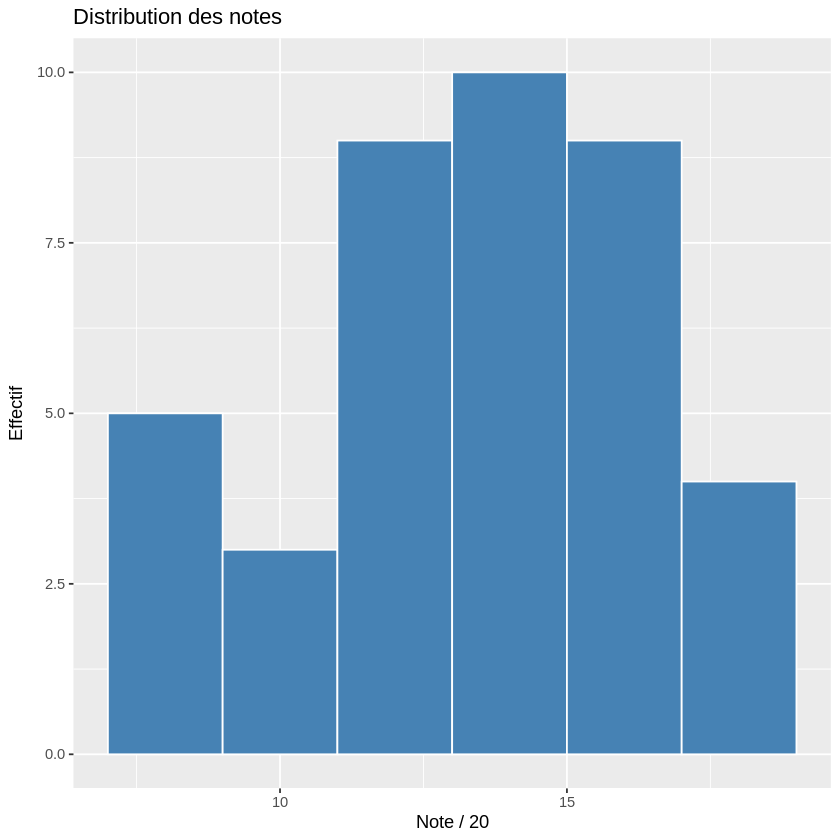

In [ ]:
ggplot(etudiants, aes(x = note)) +
  geom_histogram(binwidth = 2, fill = "steelblue", color = "white") +
  labs(title = "Distribution des notes", x = "Note / 20", y = "Effectif")

### Exercice 1.1 (Histogramme ggplot2)
Tracer l'histogramme de `heures_revision` avec ggplot2 (titre + axes nommés + couleur de votre choix).

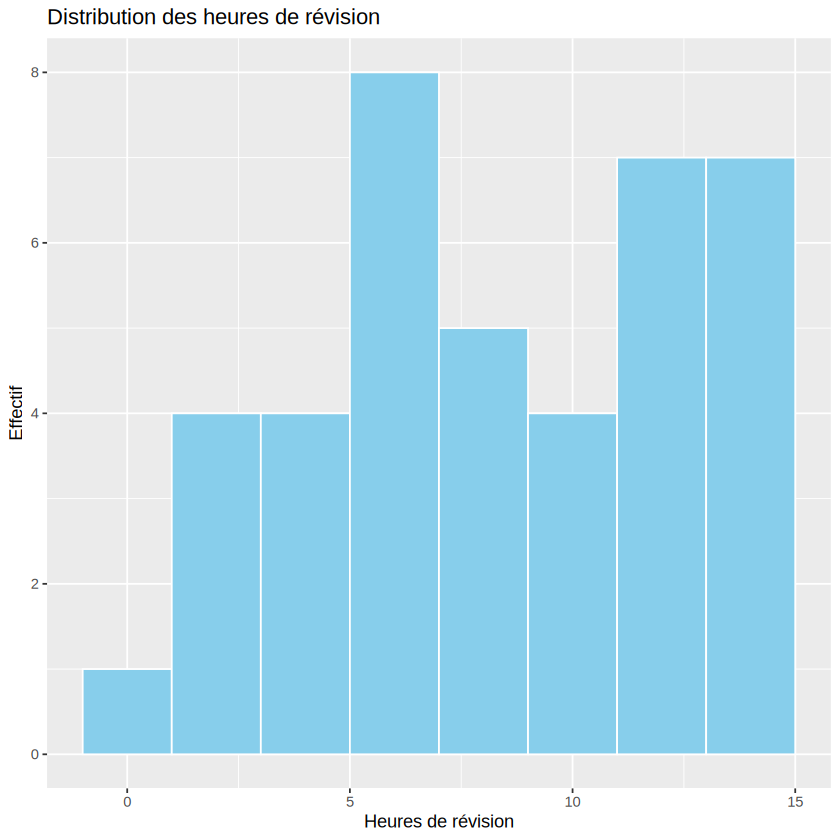

In [9]:
library(ggplot2)

ggplot(etudiants, aes(x = heures_revision)) +
  geom_histogram(binwidth = 2, fill = "skyblue", color = "white") +
  labs(
    title = "Distribution des heures de révision",
    x = "Heures de révision",
    y = "Effectif"
  )

## 2. Comparer des groupes : geom_boxplot()
Équivalent de `boxplot(note ~ groupe, data = etudiants)` vu en séquence 2.

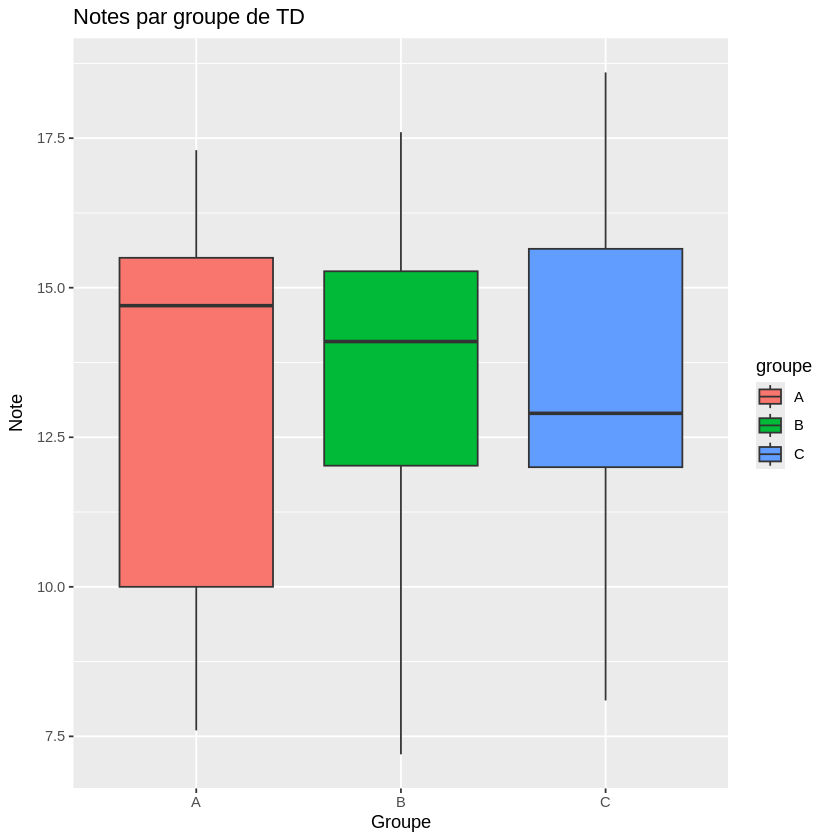

In [ ]:
ggplot(etudiants, aes(x = groupe, y = note, fill = groupe)) +
  geom_boxplot() +
  labs(title = "Notes par groupe de TD", x = "Groupe", y = "Note")

### Exercice 2.1 (Boxplot ggplot2)
Comparer la distribution des notes **par filière** avec `geom_boxplot()`.

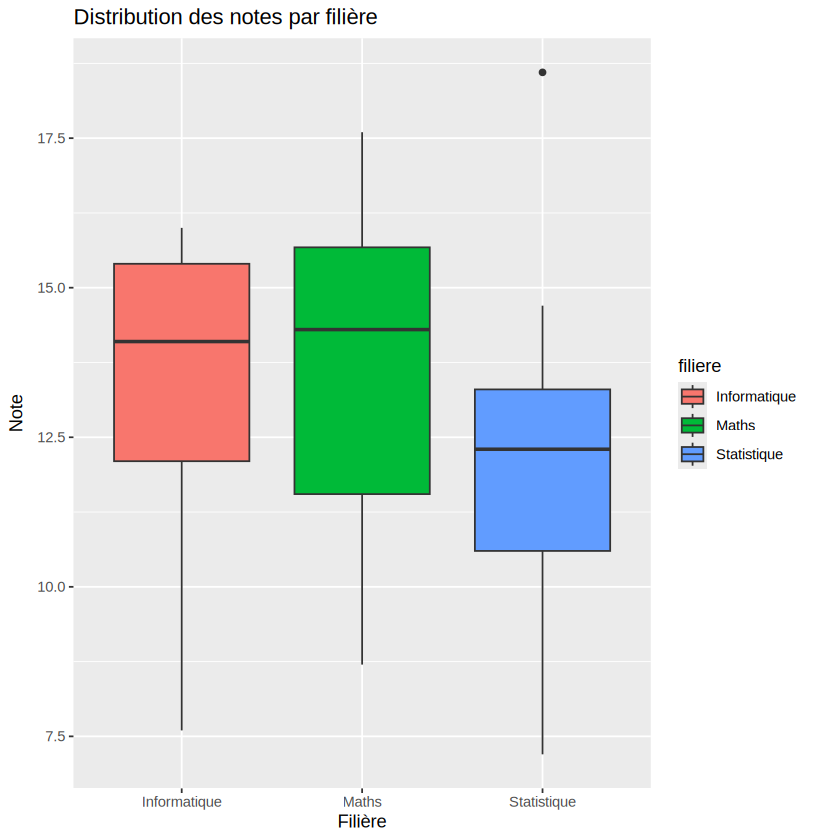

In [10]:
ggplot(etudiants, aes(x = filiere, y = note, fill = filiere)) +
  geom_boxplot() +
  labs(title = "Distribution des notes par filière",
       x = "Filière",
       y = "Note")

## 3. Relation entre deux variables : geom_point()
Équivalent de `plot()` + `abline(lm(...))` vu en séquence 2. Avec ggplot2, la droite de régression s'ajoute simplement avec `geom_smooth()`.

`geom_smooth()` using formula = 'y ~ x'


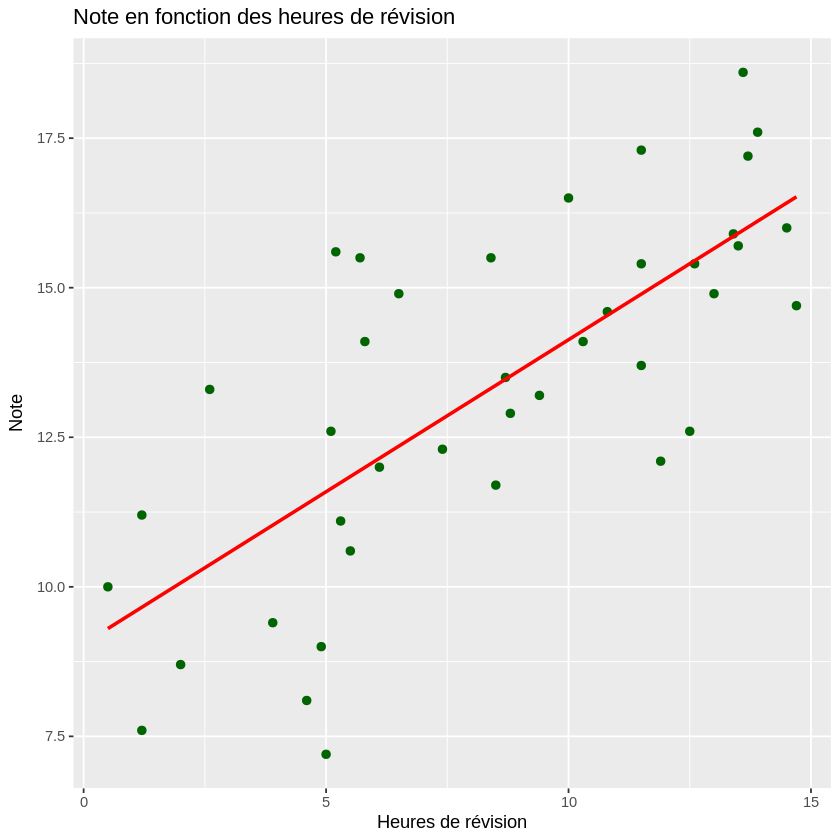

In [ ]:
ggplot(etudiants, aes(x = heures_revision, y = note)) +
  geom_point(color = "darkgreen", size = 2) +
  geom_smooth(method = "lm", color = "red", se = FALSE) +
  labs(title = "Note en fonction des heures de révision",
       x = "Heures de révision", y = "Note")

### Exercice 3.1 (Nuage de points ggplot2)
Refaire le même graphique en colorant les points selon le `genre` (indice : `aes(x = ..., y = ..., color = genre)`).

`geom_smooth()` using formula = 'y ~ x'


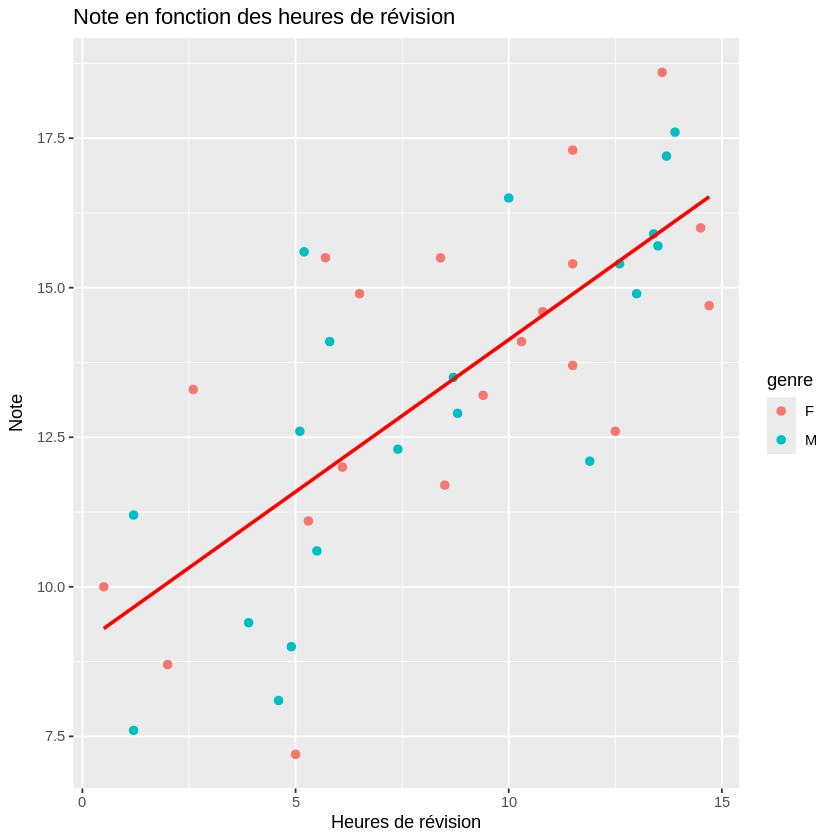

In [ ]:
ggplot(etudiants, aes(x =heures_revision, y = note, color = genre)) +
  geom_point(size = 2) +
  geom_smooth(method = "lm", color = "red", se = FALSE) +
  labs(title = "Note en fonction des heures de révision",
       x = "Heures de révision", y = "Note")

## 4. Effectifs par catégorie : geom_bar()
Contrairement à `barplot()` (qui a besoin de `table()` en amont), `geom_bar()` compte lui-même les effectifs à partir des données brutes.

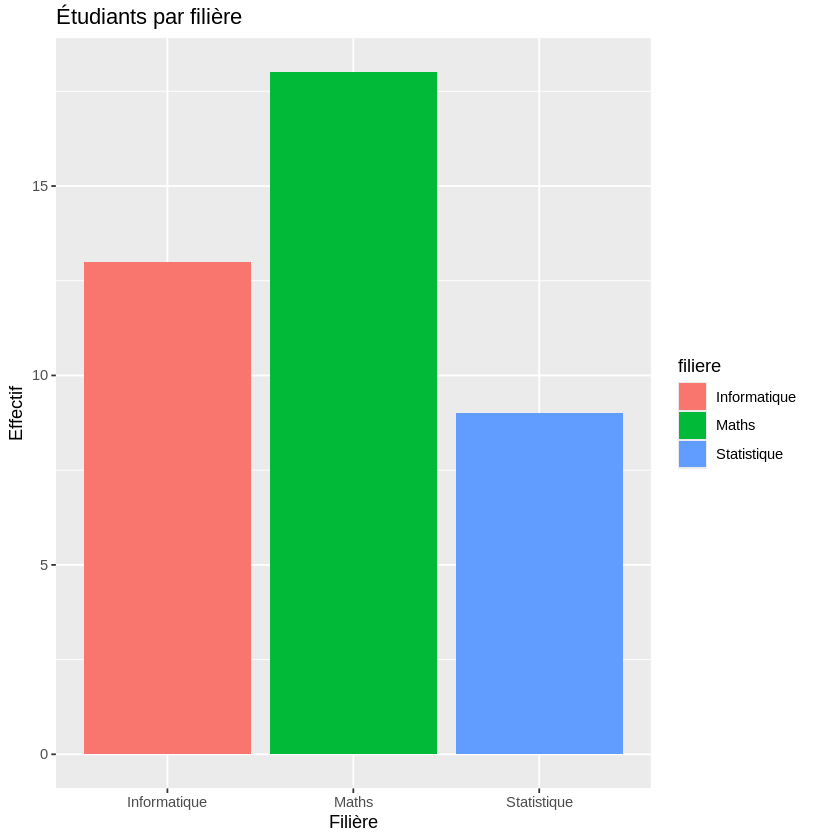

In [ ]:
ggplot(etudiants, aes(x = filiere, fill = filiere)) +
  geom_bar() +
  labs(title = "Étudiants par filière", x = "Filière", y = "Effectif")

### Exercice 4.1 (Barres ggplot2)
Tracer le diagramme en barres du nombre d'étudiants par **ville**.

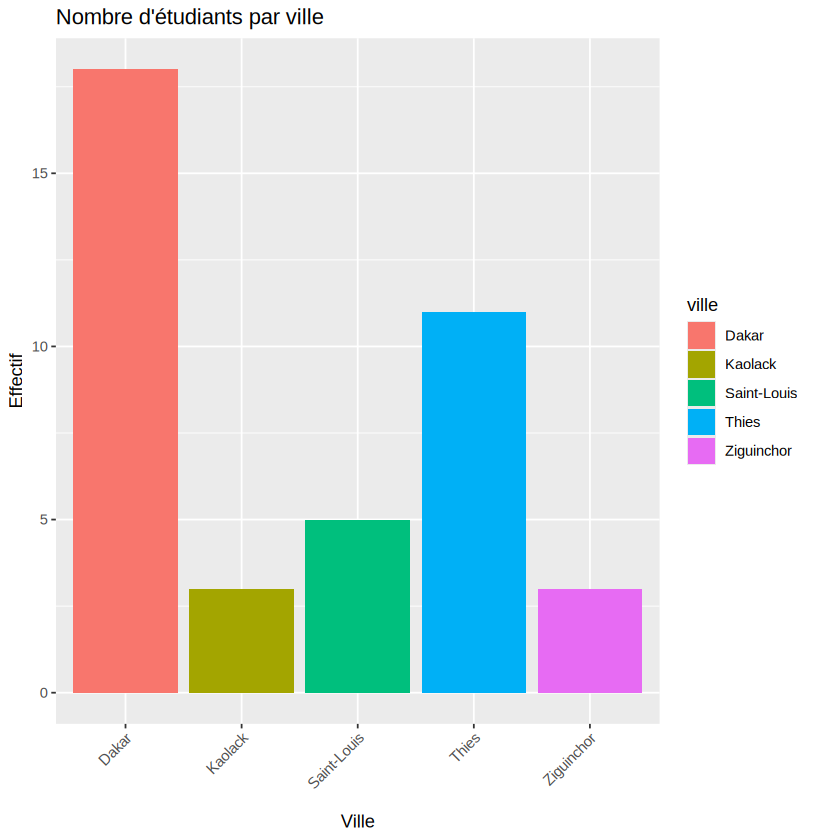

In [11]:
ggplot(etudiants, aes(x = ville, fill = ville)) +
  geom_bar() +
  labs(title = "Nombre d'étudiants par ville",
       x = "Ville",
       y = "Effectif") +
  theme(axis.text.x = element_text(angle = 45, hjust = 1))

## 5. Personnalisation : labs(), theme(), couleurs
- `labs(title=, x=, y=)` : équivalent de `main`, `xlab`, `ylab` en base R.
- `aes(color = ..., fill = ...)` : encode une variable supplémentaire par couleur.
- `theme_minimal()`, `theme_bw()`, `theme_classic()` : changent l'apparence globale du graphique.

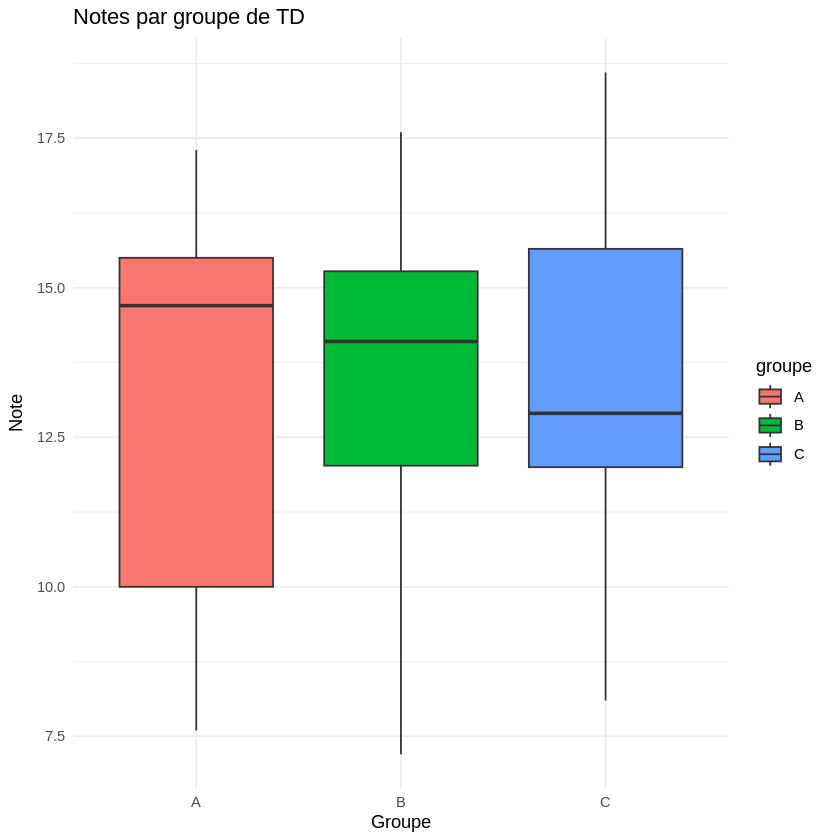

In [ ]:
ggplot(etudiants, aes(x = groupe, y = note, fill = groupe)) +
  geom_boxplot() +
  labs(title = "Notes par groupe de TD", x = "Groupe", y = "Note") +
  theme_minimal()

## 6. Récapitulatif : base R vs ggplot2

| Base R | ggplot2 |
|---|---|
| `hist(x)` | `ggplot(df, aes(x)) + geom_histogram()` |
| `boxplot(y ~ g, data)` | `ggplot(df, aes(g, y)) + geom_boxplot()` |
| `plot(x, y)` | `ggplot(df, aes(x, y)) + geom_point()` |
| `barplot(table(x))` | `ggplot(df, aes(x)) + geom_bar()` |
| `main=, xlab=, ylab=` | `labs(title=, x=, y=)` |
| boucle manuelle par groupe | `facet_wrap(~ groupe)` |